# Convolutional neural networks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Anatole-1/exercices-machine-learning/blob/main/03_convolutional_neural_networks.ipynb)

1. Exercise 1 – Sign Language MNIST (24 letters)
2. Exercise 2 – Sign Language Digits (10 digits, colour images)
3. Exercises 3 and 4 – Flowers: CNN with data augmentation, then transfer learning with VGG16

Run the notebook from the repository folder (the data files are in `data/`). In Google Colab, the first code cell clones the repository automatically.

In [ ]:
# Google Colab: get the data files by cloning the repository
import os, subprocess
if 'google.colab' in str(get_ipython()) and not os.path.exists('data'):
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/Anatole-1/exercices-machine-learning.git'], check=True)
    os.chdir('exercices-machine-learning')

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
rng=np.random.default_rng() #seed = random

## Exercise 1


[Kaggles sign-language-mnist-dataset](https://www.kaggle.com/datasets/datamunge/sign-language-mnist/code)

bw 28x28-pixel images of hand-gesture alphabets A-Y (without  J),
27455 training- and 7172 test-images.



![figure](images/03_ex1_1.png)







![figure](images/03_ex1_2.png)

Calculate the predictions for a random test image and draw a picture like below.
Draw also a picture showing the wrongly classified test-images.

![figure](images/03_ex1_3.png)

In [ ]:
# extract the Sign Language MNIST data
import zipfile
if not os.path.exists('data/sign_mnist/sign_mnist_train.csv'):
    with zipfile.ZipFile('data/sign_mnist.zip') as z:
        z.extractall('data')
print(sorted(os.listdir('data/sign_mnist')))

['sign_mnist_test.csv', 'sign_mnist_train.csv']


In [ ]:
#read as np.array
train_data=np.loadtxt('data/sign_mnist/sign_mnist_train.csv',delimiter=',',skiprows=1)
test_data=np.loadtxt('data/sign_mnist/sign_mnist_test.csv',delimiter=',',skiprows=1)

In [ ]:
print(train_data.shape)
print(test_data.shape)

(27455, 785)
(7172, 785)


In [ ]:
xtrain=train_data[:,1:]/255.0 #pixels to 0...1
ytrain=train_data[:,0] #classes
xtest=test_data[:,1:]/255.0
ytest=test_data[:,0]


In [ ]:
#images to 3D arrays, shape (28,28,1)
mtrain=xtrain.shape[0]
mtest=xtest.shape[0]
xtrain=xtrain.reshape((mtrain,28,28,1))
xtest=xtest.reshape((mtest,28,28,1))

In [ ]:
print(xtrain.shape)
print(xtest.shape)

(27455, 28, 28, 1)
(7172, 28, 28, 1)


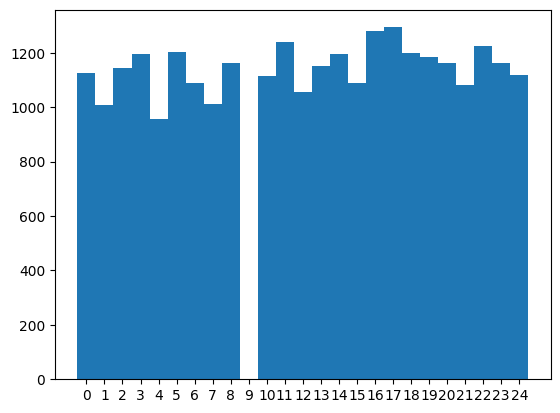

In [ ]:
#distribution of classes
plt.hist(ytrain,bins=np.arange(-0.5,25.5,1))
plt.xticks(np.arange(0,25,1))
plt.show()

In [ ]:
#class y=9 is missing (represents letter J))
#decrease classes 10...24 by one
ytrain[ytrain>9]=ytrain[ytrain>9]-1
ytest[ytest>9]=ytest[ytest>9]-1

Y=['A','B','C','D','E','F','G','H','I','K','L','M',
   'N','O','P','Q','R','S','T','U','V','W','X','Y']

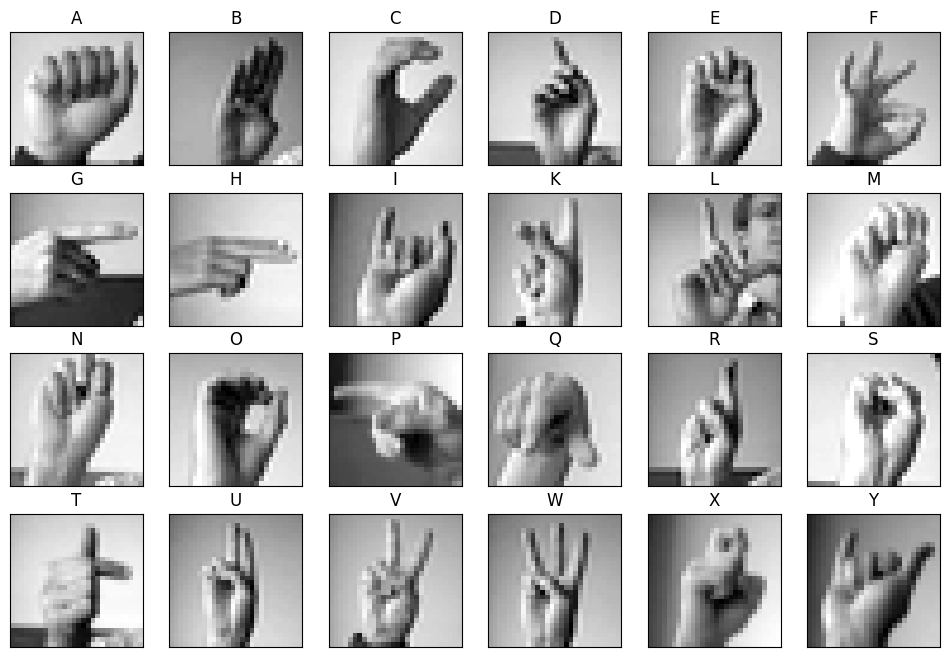

In [ ]:
#example images
plt.figure(figsize=(12,8))
for k in range(24):
    xtraink=xtrain[ytrain==k,:]
    mk=xtraink.shape[0]
    indk=rng.integers(mk)
    imgk=xtraink[indk,:].reshape((28,28))
    plt.subplot(4,6,k+1)
    plt.imshow(imgk, cmap='gray')
    plt.xticks([],[])
    plt.yticks([],[])
    plt.title(Y[k])

Build and train a CNN  that achieves 99.5 % test accuracy

In [ ]:
from keras.models import Sequential
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout

n1 = 20   # number of filters in the first convolutional layer
n2 = 40   # number of filters in the second convolutional layer
n3 = 100  # number of neurons in the hidden layer

model = Sequential()
model.add(Input(shape=(28, 28, 1)))
model.add(Conv2D(filters=n1, kernel_size=5, activation='relu'))
model.add(MaxPooling2D(pool_size=2))
model.add(Conv2D(filters=n2, kernel_size=5, activation='relu'))
model.add(MaxPooling2D(pool_size=2))
model.add(Flatten())
model.add(Dropout(0.5))
model.add(Dense(n3, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(24, activation='softmax'))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 20)     │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 20)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 40)       │        20,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 40)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 640)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 640)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │        64,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │         2,424 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 87,084 (340.17 KB)

 Trainable params: 87,084 (340.17 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from keras.optimizers import Adam

model.compile(optimizer=Adam(0.001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
from keras.callbacks import ModelCheckpoint

callback = ModelCheckpoint(
    filepath='sign_mnist_cnn.weights.h5',
    save_weights_only=True,
    monitor='val_accuracy',
    mode='max',
    save_best_only=True,
    verbose=1
)

history = model.fit(
    xtrain, ytrain,
    epochs=500,
    batch_size=1000,
    validation_data=(xtest, ytest),
    callbacks=[callback]
)

Epoch 1/500
23/28 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9950 - loss: 0.0170
Epoch 1: val_accuracy improved from None to 0.97839, saving model to /content/drive/MyDrive/sign_mnist_cnn.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/sign_mnist_cnn.weights.h5
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9950 - loss: 0.0169 - val_accuracy: 0.9784 - val_loss: 0.0840
Epoch 2/500
24/28 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9936 - loss: 0.0208
Epoch 2: val_accuracy improved from 0.97839 to 0.98034, saving model to /content/drive/MyDrive/sign_mnist_cnn.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/sign_mnist_cnn.weights.h5
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9936 - loss: 0.0195 - val_accuracy: 0.9803 - val_loss: 0.0736
Epoch 3/500
23/28 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9929 - loss: 0.0210
Epoch 3: val_accuracy did not improve from 0.98034
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 

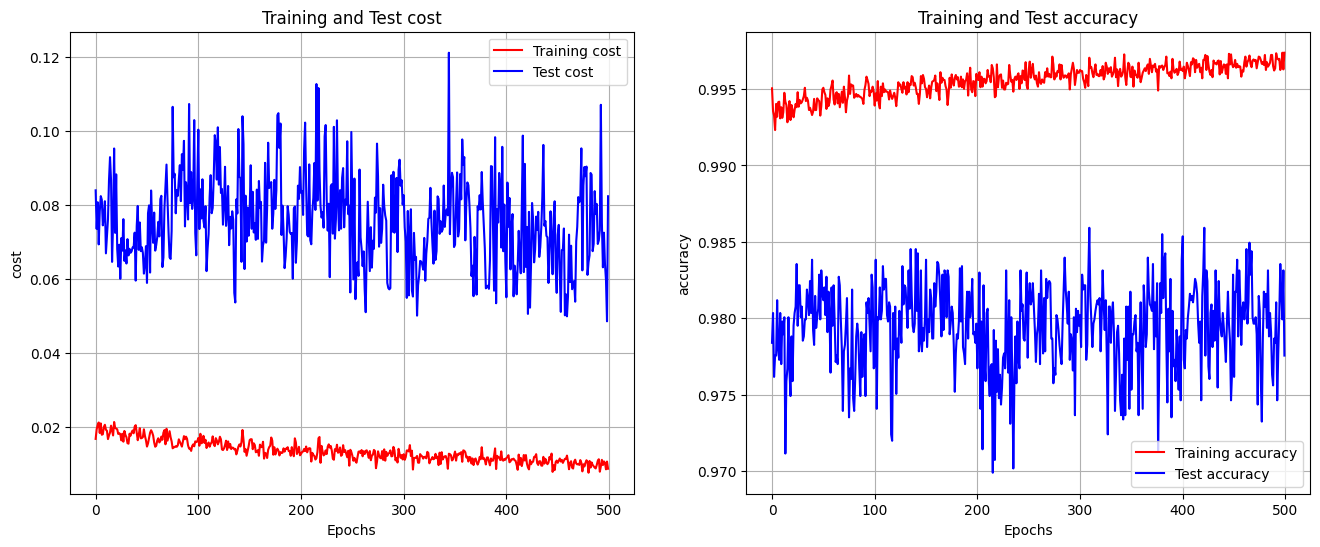

In [ ]:
train_cost = history.history['loss']
test_cost = history.history['val_loss']
train_acc = history.history['accuracy']
test_acc = history.history['val_accuracy']

plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
plt.plot(train_cost, 'r', label='Training cost')
plt.plot(test_cost, 'b', label='Test cost')
plt.title('Training and Test cost')
plt.xlabel('Epochs')
plt.ylabel('cost')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(train_acc, 'r', label='Training accuracy')
plt.plot(test_acc, 'b', label='Test accuracy')
plt.title('Training and Test accuracy')
plt.xlabel('Epochs')
plt.ylabel('accuracy')
plt.legend()
plt.grid()

plt.show()

In [ ]:
model.load_weights('sign_mnist_cnn.weights.h5')

train_loss, train_acc = model.evaluate(xtrain, ytrain, verbose=0)
test_loss, test_acc = model.evaluate(xtest, ytest, verbose=0)

print("train_acc =", train_acc)
print("test_acc =", test_acc)

train_acc = 1.0
test_acc = 0.9859174489974976


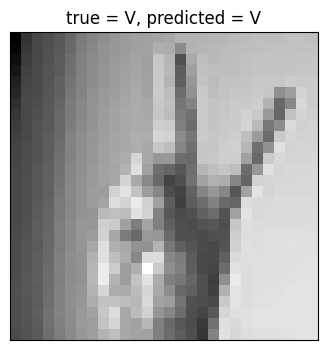

probabilities = [[2.0857356e-24 6.5996245e-29 1.9298662e-24 2.2183491e-13 1.8948685e-28
  2.9042337e-15 9.2054929e-27 5.3967484e-26 1.0547407e-15 6.6172649e-12
  1.6328997e-07 3.3770750e-23 2.4713142e-16 2.1732341e-26 4.6111369e-19
  5.7124783e-22 2.1036581e-17 2.8915208e-15 3.8065019e-17 6.2733248e-24
  9.9999976e-01 9.2220304e-08 5.4494847e-17 1.1965054e-11]]


In [ ]:
# prediction for a random test image
ind = rng.integers(mtest)

xtest_ind = xtest[ind:ind+1, :]
ytrue = int(ytest[ind])

apred = model.predict(xtest_ind, verbose=0)
ypred = int(np.argmax(apred))

plt.figure(figsize=(4, 4))
plt.imshow(xtest[ind, :, :, 0], cmap='gray')
plt.xticks([], [])
plt.yticks([], [])
plt.title('true = {}, predicted = {}'.format(Y[ytrue], Y[ypred]))
plt.show()

print("probabilities =", apred)

number of wrongly classified test images = 150


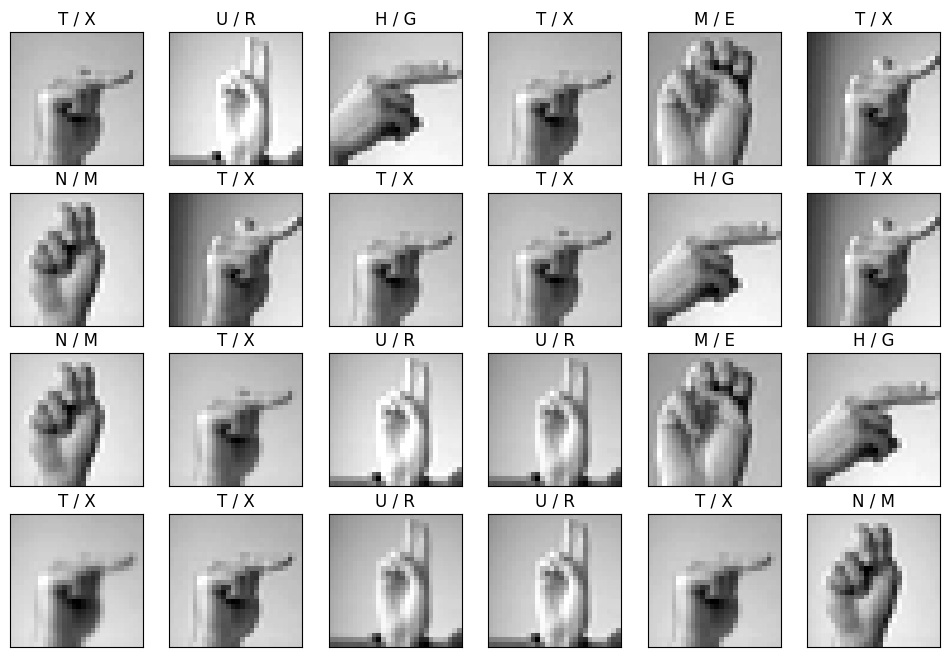

In [ ]:
# wrongly classified test images
apred = model.predict(xtest, verbose=0)
ypred = np.argmax(apred, axis=1)

wrong = np.where(ypred != ytest)[0]
print("number of wrongly classified test images =", len(wrong))

plt.figure(figsize=(12, 8))

nshow = min(24, len(wrong))
for k in range(nshow):
    ind = wrong[k]
    plt.subplot(4, 6, k + 1)
    plt.imshow(xtest[ind, :, :, 0], cmap='gray')
    plt.xticks([], [])
    plt.yticks([], [])
    plt.title('{} / {}'.format(Y[int(ytest[ind])], Y[int(ypred[ind])]))

plt.show()

## Exercise 2


[Sign-Language-Digits-Dataset](https://github.com/ardamavi/Sign-Language-Digits-Dataset)

100x100x3 images of hand-gesture numbers 0-9, total 2059 images.



Build and train a CNN  that achieves 99.5 % test accuracy. Draw a picture showing the wrongly classified test-images.

![figure](images/03_ex2_1.png)

In [ ]:
#get the images
import subprocess
if not os.path.exists('Sign-Language-Digits-Dataset'):
    subprocess.run(['git','clone','https://github.com/ardamavi/Sign-Language-Digits-Dataset.git'],check=True)

Cloning into 'Sign-Language-Digits-Dataset'...
remote: Enumerating objects: 2095, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 2095 (delta 2), reused 0 (delta 0), pack-reused 2089 (from 1)
Receiving objects: 100% (2095/2095), 15.07 MiB | 17.49 MiB/s, done.
Resolving deltas: 100% (660/660), done.


In [ ]:
#number of images
import os
dir='Sign-Language-Digits-Dataset/Dataset'
m=0
for k in range(10):
  dirk=dir+'/'+str(k)
  filenames=os.listdir(dirk)
  mk=len(filenames)
  m+=mk
  print(str(k)+': '+str(mk))
print(m)

0: 205
1: 206
2: 206
3: 206
4: 207
5: 207
6: 207
7: 206
8: 208
9: 204
2062


In [ ]:
#remove images with shape != (100,100,3)
for k in range(10):
  dirk=dir+'/'+str(k)
  filenames=os.listdir(dirk)
  for filename in filenames:
    path=dirk+'/'+filename
    img=plt.imread(path)
    if img.shape!=(100,100,3):
      print(img.shape)
      os.remove(path)

(3024, 3024, 3)
(3024, 3024, 3)
(3024, 3024, 3)


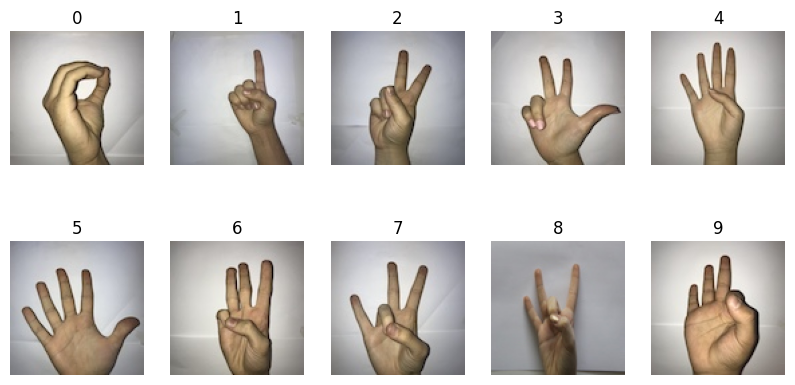

In [ ]:
#example images
plt.figure(figsize=(10,5))

for k in range(10):
  dirk=dir+'/'+str(k)
  filenames=os.listdir(dirk)
  img=plt.imread(dirk+'/'+filenames[0])
  plt.subplot(2,5,k+1)
  plt.imshow(img)
  plt.axis('off')
  plt.title(str(k))

In [ ]:
#create folders for test/validation data
test_already_split=os.path.exists('Sign-Language-Digits-Dataset/test')
for k in range(10):
  os.makedirs('Sign-Language-Digits-Dataset/test/'+str(k),exist_ok=True)

In [ ]:
#take 30% of images as test/validation
import shutil
if not test_already_split:  # do the split only once
  for k in range(10):
    dirk=dir+'/'+str(k)
    filenames=os.listdir(dirk)
    nk=len(filenames)
    mk=int(0.3*nk)
    testdirk='Sign-Language-Digits-Dataset/test/'+str(k)+'/'
    for m in range(mk):
      shutil.move(dirk+'/'+filenames[m],testdirk)

In [ ]:
train_dir='Sign-Language-Digits-Dataset/Dataset/'
test_dir='Sign-Language-Digits-Dataset/test/'
for k in range(10):
  train_k='Sign-Language-Digits-Dataset/Dataset/'+str(k)
  test_k='Sign-Language-Digits-Dataset/test/'+str(k)
  print('k = '+str(k)+': train '+str(len(os.listdir(train_k)))+', test '+str(len(os.listdir(test_k))))


k = 0: train 144, test 61
k = 1: train 145, test 61
k = 2: train 145, test 61
k = 3: train 145, test 61
k = 4: train 145, test 62
k = 5: train 145, test 62
k = 6: train 145, test 62
k = 7: train 143, test 60
k = 8: train 146, test 62
k = 9: train 143, test 61


In [ ]:
from keras.utils import image_dataset_from_directory

img_height = 100
img_width = 100
batch_size = 32

train_dataset = image_dataset_from_directory(
    train_dir,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

test_dataset = image_dataset_from_directory(
    test_dir,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    shuffle=False
)

Found 1446 files belonging to 10 classes.
Found 613 files belonging to 10 classes.


images shape: (32, 100, 100, 3)
labels shape: (32,)


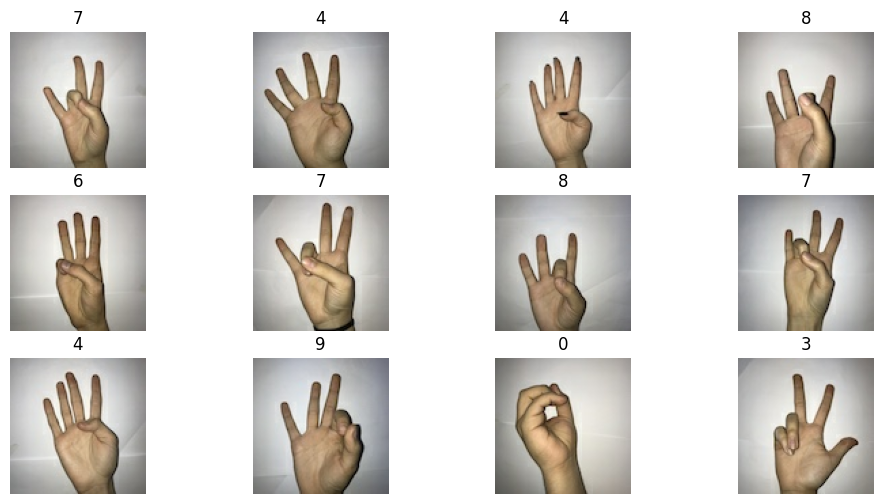

In [ ]:
for images, labels in train_dataset:
    print('images shape:', images.shape)
    print('labels shape:', labels.shape)

    plt.figure(figsize=(12, 6))
    for k in range(min(batch_size, 12)):
        plt.subplot(3, 4, k + 1)
        plt.imshow(images[k].numpy().astype("uint8"))
        plt.axis('off')
        plt.title(int(labels[k]))
    plt.show()
    break

In [ ]:
from keras.models import Sequential
from keras.layers import Input, Rescaling, Conv2D, MaxPooling2D, Flatten, Dropout, Dense

model = Sequential()
model.add(Input(shape=(img_height, img_width, 3)))
model.add(Rescaling(1/255.0))
model.add(Conv2D(32, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Dropout(0.2))
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Dropout(0.2))
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Flatten())
model.add(Dropout(0.5))
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(10, activation='softmax'))

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 21, 21, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 504,394 (1.92 MB)

 Trainable params: 504,394 (1.92 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from keras.optimizers import Adam

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=Adam(learning_rate=0.001),
    metrics=['accuracy']
)

In [ ]:
from keras.callbacks import ModelCheckpoint

callback = ModelCheckpoint(
    filepath='sign_language_digits_cnn.weights.h5',
    monitor='val_accuracy',
    save_weights_only=True,
    save_best_only=True,
    verbose=1
)

history = model.fit(
    train_dataset,
    epochs=100,
    validation_data=test_dataset,
    callbacks=[callback]
)

Epoch 1/100
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.1109 - loss: 2.3290
Epoch 1: val_accuracy improved from None to 0.09951, saving model to /content/drive/MyDrive/sign_language_digits_cnn.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/sign_language_digits_cnn.weights.h5
46/46 ━━━━━━━━━━━━━━━━━━━━ 15s 150ms/step - accuracy: 0.1010 - loss: 2.3137 - val_accuracy: 0.0995 - val_loss: 2.3020
Epoch 2/100
44/46 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1135 - loss: 2.3021
Epoch 2: val_accuracy improved from 0.09951 to 0.19576, saving model to /content/drive/MyDrive/sign_language_digits_cnn.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/sign_language_digits_cnn.weights.h5
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.1120 - loss: 2.3020 - val_accuracy: 0.1958 - val_loss: 2.3000
Epoch 3/100
44/46 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1127 - loss: 2.2930
Epoch 3: val_accuracy improved from 0.19576 to 0.38662, savi

In [ ]:
model.load_weights('sign_language_digits_cnn.weights.h5')

print(model.evaluate(train_dataset, verbose=0))
print(model.evaluate(test_dataset, verbose=0))

[0.000639063713606447, 1.0]
[0.02507839910686016, 0.9934747219085693]


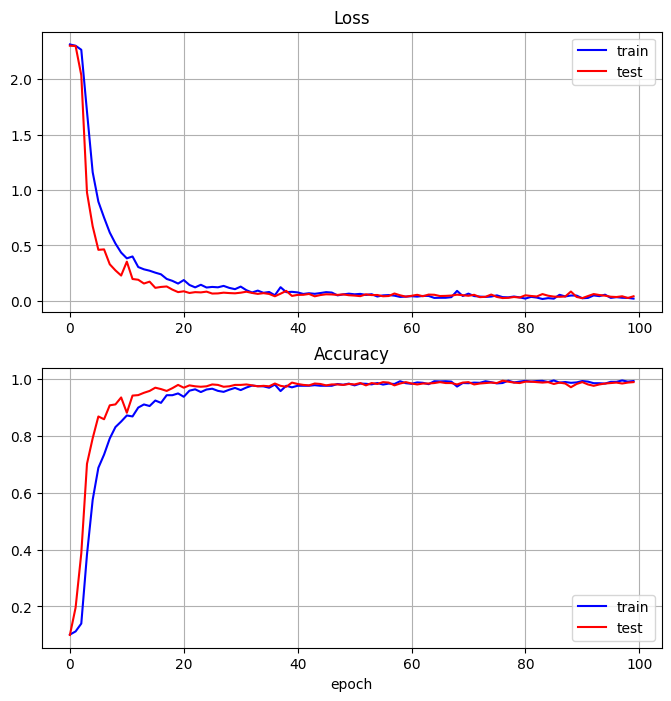

In [ ]:
plt.figure(figsize=(8, 8))

plt.subplot(2, 1, 1)
plt.title('Loss')
plt.plot(history.history['loss'], color='b', label='train')
plt.plot(history.history['val_loss'], color='r', label='test')
plt.legend()
plt.grid()

plt.subplot(2, 1, 2)
plt.title('Accuracy')
plt.plot(history.history['accuracy'], color='b', label='train')
plt.plot(history.history['val_accuracy'], color='r', label='test')
plt.legend()
plt.grid()
plt.xlabel('epoch')

plt.show()

In [ ]:
atest_pred = model.predict(test_dataset, verbose=0)
test_labels_pred = np.argmax(atest_pred, axis=1)

In [ ]:
test_labels = np.array([])

for images, labels in test_dataset:
    test_labels = np.concatenate((test_labels, labels.numpy()))

test_labels = test_labels.astype(int)

print(test_labels.shape)
print(test_labels_pred.shape)

(613,)
(613,)


number of wrongly classified test images = 4


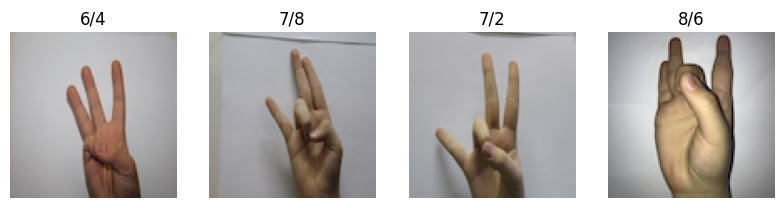

In [ ]:
wrong_paths = np.array(test_dataset.file_paths)[test_labels != test_labels_pred]

print("number of wrongly classified test images =", len(wrong_paths))

plt.figure(figsize=(15, 10))

nshow = min(24, len(wrong_paths))
for k in range(nshow):
    path = wrong_paths[k]
    img = plt.imread(path)
    true_label = int(test_labels[test_labels != test_labels_pred][k])
    pred_label = int(test_labels_pred[test_labels != test_labels_pred][k])

    plt.subplot(4, 6, k + 1)
    plt.imshow(img)
    plt.axis('off')
    plt.title(f'{true_label}/{pred_label}')

plt.show()

## Exercises 3 and 4


[Flowers-dataset](https://www.tensorflow.org/datasets/catalog/tf_flowers)

Contains 3670 images of flowers daisy, dandelion, rose, tulip and sunflower.



![figure](images/03_ex3_4_1.png)

In [ ]:
import tensorflow as tf
import pathlib
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
archive = tf.keras.utils.get_file(origin=dataset_url, extract=True)
data_dir = pathlib.Path(archive).with_suffix('')

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
data_dir

PosixPath('/root/.keras/datasets/flower_photos')

In [ ]:
zip_dir_base = os.path.dirname(data_dir)
for root, dirs, files in os.walk(zip_dir_base):
    if root.count(os.sep) - zip_dir_base.count(os.sep) <= 2:
        print(root)

In [ ]:
# folder containing the 5 class folders (daisy, dandelion, roses, sunflowers, tulips)
# (its exact location depends on the Keras version)
base_dir = None
for root, dirs, files in os.walk(os.path.dirname(data_dir)):
    if 'roses' in dirs and 'tulips' in dirs:
        base_dir = root
        break
base_dir

'/root/.keras/datasets/flower_photos.tgz/flower_photos'

In [ ]:
categories = ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']

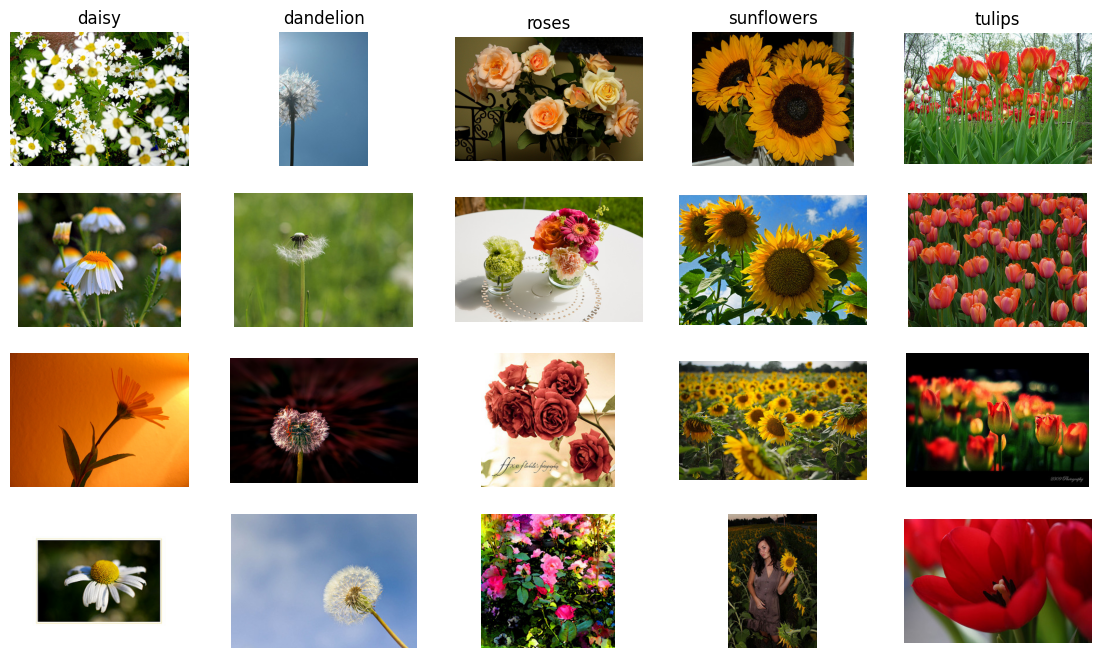

In [ ]:
#example images
plt.figure(figsize=(14,8))
for k in range(5):
  category=categories[k]
  flower_folder=os.path.join(base_dir, category)
  flower_names=os.listdir(flower_folder)
  m=len(flower_names)
  n=rng.integers(0,m,4)
  for i in range(4):
    flower_name=flower_names[n[i]]
    flower_path=os.path.join(flower_folder,flower_name)
    img=plt.imread(flower_path)
    plt.subplot(4,5,1+k+i*5)
    plt.imshow(img)
    plt.axis('off')
    if i==0:
      plt.title(category)


Split the images to train and test (70%/30%) and

In [ ]:
from keras.utils import image_dataset_from_directory

img_height = 200
img_width = 200
batch_size = 32
seed = 123

train_dataset = image_dataset_from_directory(
    base_dir,
    validation_split=0.3,
    subset='training',
    seed=seed,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

test_dataset = image_dataset_from_directory(
    base_dir,
    validation_split=0.3,
    subset='validation',
    seed=seed,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    shuffle=False
)

class_names = train_dataset.class_names
print(class_names)

Found 3670 files belonging to 5 classes.
Using 2569 files for training.
Found 3670 files belonging to 5 classes.
Using 1101 files for validation.
['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


images shape: (32, 200, 200, 3)
labels shape: (32,)


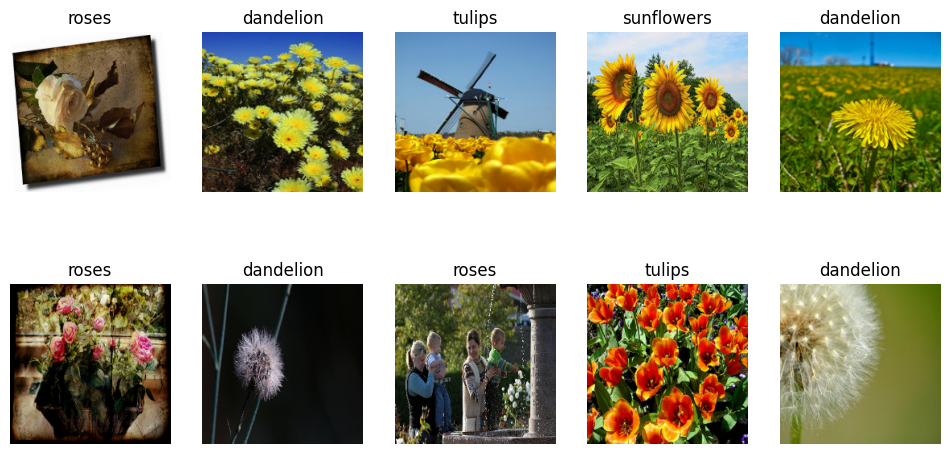

In [ ]:
for images, labels in train_dataset:
    print('images shape:', images.shape)
    print('labels shape:', labels.shape)

    plt.figure(figsize=(12, 6))
    for k in range(10):
        plt.subplot(2, 5, k + 1)
        plt.imshow(images[k].numpy().astype("uint8"))
        plt.axis('off')
        plt.title(class_names[int(labels[k])])
    plt.show()
    break

**EXERCISE 3**

Build and train a CNN that achieves 85% test accuracy. Use image size 200x200 and data-augmentation.

In [ ]:
from keras.layers import RandomFlip, RandomRotation, RandomZoom, RandomTranslation
from keras.models import Sequential

Data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.2),
    RandomTranslation(0.2, 0.2)
])

In [ ]:
from keras.models import Sequential
from keras.layers import Input, Rescaling, Conv2D, MaxPooling2D, Flatten, Dropout, Dense

model = Sequential()
model.add(Input(shape=(img_height, img_width, 3)))
model.add(Data_augmentation)
model.add(Rescaling(1/255.0))
model.add(Conv2D(32, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Flatten())
model.add(Dropout(0.5))
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(5, activation='softmax'))

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 198, 198, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 99, 99, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 97, 97, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 46, 46, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 23, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 21, 21, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     1,638,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,880,005 (7.17 MB)

 Trainable params: 1,880,005 (7.17 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from keras.optimizers import Adam

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=Adam(learning_rate=0.0005),
    metrics=['accuracy']
)

In [ ]:
from keras.callbacks import ModelCheckpoint

callback = ModelCheckpoint(
    filepath='flowers_cnn.weights.h5',
    monitor='val_accuracy',
    save_weights_only=True,
    save_best_only=True,
    verbose=1
)

history = model.fit(
    train_dataset,
    epochs=100,
    validation_data=test_dataset,
    callbacks=[callback]
)

Epoch 1/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.2974 - loss: 1.5297
Epoch 1: val_accuracy improved from None to 0.43052, saving model to /content/drive/MyDrive/flowers_cnn.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/flowers_cnn.weights.h5
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 90ms/step - accuracy: 0.3519 - loss: 1.4216 - val_accuracy: 0.4305 - val_loss: 1.2702
Epoch 2/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.4555 - loss: 1.2364
Epoch 2: val_accuracy improved from 0.43052 to 0.62670, saving model to /content/drive/MyDrive/flowers_cnn.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/flowers_cnn.weights.h5
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 82ms/step - accuracy: 0.4566 - loss: 1.2432 - val_accuracy: 0.6267 - val_loss: 1.0166
Epoch 3/100
80/81 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.5439 - loss: 1.1289
Epoch 3: val_accuracy did not improve from 0.62670
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 94ms/step - accuracy: 0.5489 - lo

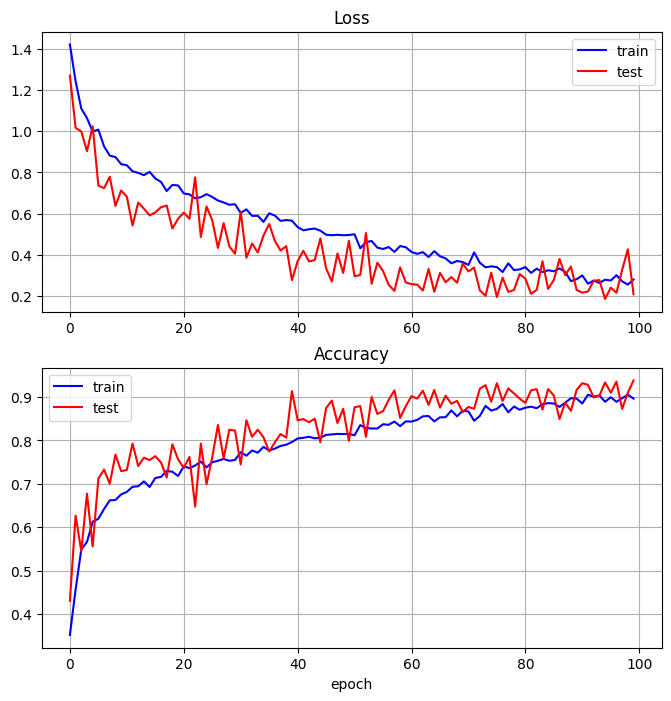

In [ ]:
plt.figure(figsize=(8, 8))

plt.subplot(2, 1, 1)
plt.title('Loss')
plt.plot(history.history['loss'], color='b', label='train')
plt.plot(history.history['val_loss'], color='r', label='test')
plt.legend()
plt.grid()

plt.subplot(2, 1, 2)
plt.title('Accuracy')
plt.plot(history.history['accuracy'], color='b', label='train')
plt.plot(history.history['val_accuracy'], color='r', label='test')
plt.legend()
plt.grid()
plt.xlabel('epoch')

plt.show()

In [ ]:
model.load_weights('flowers_cnn.weights.h5')

print(model.evaluate(train_dataset, verbose=0))
print(model.evaluate(test_dataset, verbose=0))

[0.2598278224468231, 0.9069676995277405]
[0.20856539905071259, 0.9382379651069641]


**EXERCISE 4**

Use VGG16 to achieve 90% test accuracy.

In [ ]:
from keras.utils import image_dataset_from_directory

img_height_vgg = 224
img_width_vgg = 224
batch_size_vgg = 32
seed = 123

train_dataset_vgg = image_dataset_from_directory(
    base_dir,
    validation_split=0.3,
    subset='training',
    seed=seed,
    image_size=(img_height_vgg, img_width_vgg),
    batch_size=batch_size_vgg
)

test_dataset_vgg = image_dataset_from_directory(
    base_dir,
    validation_split=0.3,
    subset='validation',
    seed=seed,
    image_size=(img_height_vgg, img_width_vgg),
    batch_size=batch_size_vgg,
    shuffle=False
)

class_names = train_dataset_vgg.class_names
print(class_names)

Found 3670 files belonging to 5 classes.
Using 2569 files for training.
Found 3670 files belonging to 5 classes.
Using 1101 files for validation.
['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [ ]:
from keras.applications import VGG16

conv_base = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

conv_base.trainable = False
conv_base.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
from keras.layers import RandomFlip, RandomRotation, RandomZoom, RandomTranslation
from keras.models import Sequential

Data_augmentation_vgg = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.2),
    RandomTranslation(0.2, 0.2)
])

In [ ]:
from keras.applications.vgg16 import preprocess_input

train_dataset_vgg = train_dataset_vgg.map(
    lambda x, y: (preprocess_input(x), y)
)

test_dataset_vgg = test_dataset_vgg.map(
    lambda x, y: (preprocess_input(x), y)
)

In [ ]:
from keras.models import Sequential
from keras.layers import Input, Flatten, Dropout, Dense

model = Sequential()
model.add(Input(shape=(224, 224, 3)))
model.add(Data_augmentation_vgg)
model.add(conv_base)
model.add(Flatten())
model.add(Dropout(0.5))
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(5, activation='softmax'))

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_4 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,926,725 (68.39 MB)

 Trainable params: 3,212,037 (12.25 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
from keras.optimizers import Adam

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=Adam(learning_rate=0.0005),
    metrics=['accuracy']
)

In [ ]:
from keras.callbacks import ModelCheckpoint

callback = ModelCheckpoint(
    filepath='flowers_VGG16.weights.h5',
    monitor='val_accuracy',
    save_weights_only=True,
    save_best_only=True,
    verbose=1
)

history = model.fit(
    train_dataset_vgg,
    epochs=30,
    validation_data=test_dataset_vgg,
    callbacks=[callback]
)

Epoch 1/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step - accuracy: 0.4284 - loss: 8.9641
Epoch 1: val_accuracy improved from None to 0.58583, saving model to /content/drive/MyDrive/flowers_VGG16.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/flowers_VGG16.weights.h5
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 238ms/step - accuracy: 0.5010 - loss: 4.5081 - val_accuracy: 0.5858 - val_loss: 1.0274
Epoch 2/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.5819 - loss: 1.2093
Epoch 2: val_accuracy improved from 0.58583 to 0.70118, saving model to /content/drive/MyDrive/flowers_VGG16.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/flowers_VGG16.weights.h5
81/81 ━━━━━━━━━━━━━━━━━━━━ 24s 300ms/step - accuracy: 0.5960 - loss: 1.1687 - val_accuracy: 0.7012 - val_loss: 0.7150
Epoch 3/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.6273 - loss: 0.9854
Epoch 3: val_accuracy improved from 0.70118 to 0.79019, saving model to /content/drive/MyDrive/flowers_

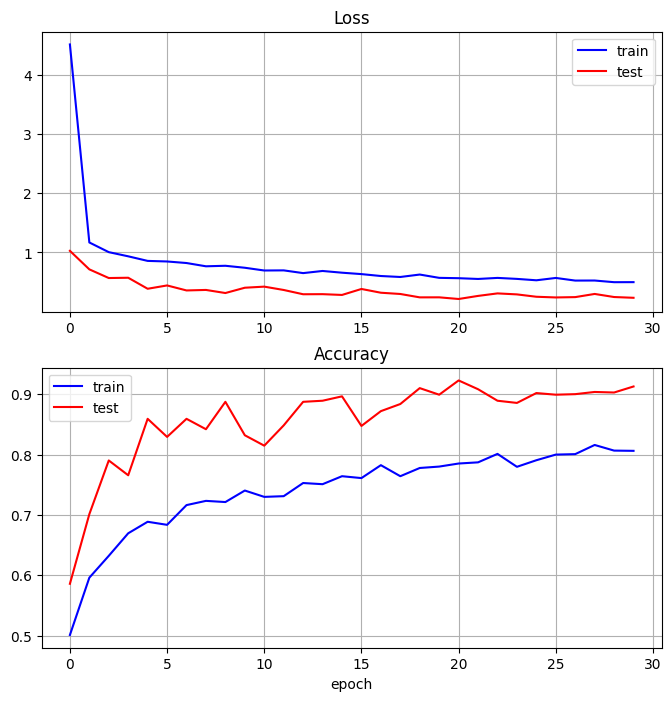

In [ ]:
plt.figure(figsize=(8, 8))

plt.subplot(2, 1, 1)
plt.title('Loss')
plt.plot(history.history['loss'], color='b', label='train')
plt.plot(history.history['val_loss'], color='r', label='test')
plt.legend()
plt.grid()

plt.subplot(2, 1, 2)
plt.title('Accuracy')
plt.plot(history.history['accuracy'], color='b', label='train')
plt.plot(history.history['val_accuracy'], color='r', label='test')
plt.legend()
plt.grid()
plt.xlabel('epoch')

plt.show()

In [ ]:
model.load_weights('flowers_VGG16.weights.h5')

print(model.evaluate(train_dataset_vgg, verbose=0))
print(model.evaluate(test_dataset_vgg, verbose=0))

[0.2200779765844345, 0.9252627491950989]
[0.2153339833021164, 0.922797441482544]
